In [1]:
from pathlib import Path
import json
import sqlite3
import sys
import time
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

# Locate the RiskLens project folder.
CURRENT = Path.cwd()

if CURRENT.name == "notebooks":
    ROOT = CURRENT.parent
elif CURRENT.name == "RiskLens":
    ROOT = CURRENT
else:
    raise ValueError(
        f"Current folder: {CURRENT}\n"
        "Please open this notebook from RiskLens/notebooks."
    )

DATA_FOLDER = ROOT / "data_processed"
DB_FILE = ROOT / "database" / "risklens.db"
OUT = ROOT / "outputs" / "R2"
MODEL_DIR = ROOT / "models"

for folder in (DB_FILE.parent, OUT, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Chronological partitions (simulation steps).
TRAIN_END_STEP = 108          # steps 0-107   -> train
VALIDATION_END_STEP = 144     # steps 108-143 -> validation; 144-179 -> test (reserved)

FEATURES = ["amount", "category"]
RANDOM_STATE = 42

# Columns that must never be predictors.
NOT_PREDICTORS = {"fraud", "transaction_id", "split", "step", "customer"}
assert set(FEATURES).isdisjoint(NOT_PREDICTORS), "A forbidden column is in FEATURES."

print("Project folder:", ROOT)
print("Outputs folder:", OUT)
print("Predictors:", FEATURES)

Project folder: C:\Users\tiwar\Documents\RiskLens
Outputs folder: C:\Users\tiwar\Documents\RiskLens\outputs\R2
Predictors: ['amount', 'category']


In [2]:
cleaned = pd.read_csv(DATA_FOLDER / "banksim_cleaned.csv")
train = pd.read_csv(DATA_FOLDER / "banksim_train.csv")
validation = pd.read_csv(DATA_FOLDER / "banksim_validation.csv")

print("Cleaned dataset:", cleaned.shape)
print("Training dataset:", train.shape)
print("Validation dataset:", validation.shape)
print("\nThe test file exists, but this notebook does not open it.")

required_columns = ["transaction_id", "step", "amount", "category", "fraud"]

for name, frame in [("cleaned", cleaned), ("train", train), ("validation", validation)]:
    assert set(required_columns).issubset(frame.columns), f"{name}: required columns are missing."
    assert frame[required_columns].notna().all().all(), f"{name}: unexpected missing values."
    assert frame["transaction_id"].is_unique, f"{name}: duplicate transaction IDs."
    assert set(frame["fraud"].unique()) == {0, 1}, f"{name}: both classes are required."
    assert np.isfinite(frame[["step", "amount"]].to_numpy()).all()
    assert (frame["amount"] >= 0).all()

# Exact simulation steps in each partition.
assert set(cleaned["step"].unique()) == set(range(180))
assert set(train["step"].unique()) == set(range(TRAIN_END_STEP))
assert set(validation["step"].unique()) == set(range(TRAIN_END_STEP, VALIDATION_END_STEP))

# No transaction appears in both working partitions.
assert set(train["transaction_id"]).isdisjoint(validation["transaction_id"])

# Partition labels for the database copy.
cleaned["split"] = np.select(
    [cleaned["step"] < TRAIN_END_STEP, cleaned["step"] < VALIDATION_END_STEP],
    ["train", "validation"],
    default="test"
)

# The saved working files must match the cleaned dataset exactly.
for name, frame in [("train", train), ("validation", validation)]:
    expected = (
        cleaned.loc[cleaned["split"].eq(name), required_columns]
        .sort_values("transaction_id").reset_index(drop=True)
    )
    actual = (
        frame[required_columns]
        .sort_values("transaction_id").reset_index(drop=True)
    )
    pd.testing.assert_frame_equal(expected, actual, check_dtype=False)

partition_summary = pd.DataFrame([
    {
        "partition": name,
        "transactions": len(frame),
        "fraud_transactions": int(frame["fraud"].sum()),
        "first_step": int(frame["step"].min()),
        "last_step": int(frame["step"].max())
    }
    for name, frame in [("train", train), ("validation", validation)]
])

display(partition_summary)
partition_summary.to_csv(OUT / "r2_partition_check.csv", index=False)

print("PASS: saved partitions and chronological boundaries verified.")

Cleaned dataset: (594643, 11)
Training dataset: (332592, 12)
Validation dataset: (128820, 12)

The test file exists, but this notebook does not open it.


,partition,transactions,fraud_transactions,first_step,last_step
0,train,332592,4320,0,107
1,validation,128820,1440,108,143


PASS: saved partitions and chronological boundaries verified.


In [3]:
with sqlite3.connect(DB_FILE) as conn:
    cleaned.to_sql(
        "transactions", conn,
        if_exists="replace", index=False, chunksize=10000
    )

    # Enforce unique transaction IDs and speed up partition filters.
    conn.execute(
        "CREATE UNIQUE INDEX idx_risklens_transaction_id ON transactions(transaction_id)"
    )
    conn.execute("CREATE INDEX idx_risklens_split ON transactions(split)")
    conn.commit()

    stored_rows = conn.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]

assert stored_rows == len(cleaned)

print("Database saved at:", DB_FILE)
print(f"Transactions stored: {stored_rows:,}")
print("PASS: database row count matches the cleaned dataset.")

Database saved at: C:\Users\tiwar\Documents\RiskLens\database\risklens.db
Transactions stored: 594,643
PASS: database row count matches the cleaned dataset.


In [4]:
queries = {
    "overall_totals": """
        SELECT
            COUNT(*) AS transactions,
            SUM(fraud) AS fraud_transactions,
            100.0 * SUM(fraud) / COUNT(*) AS fraud_rate_percent
        FROM transactions
    """,

    "split_summary": """
        SELECT
            split,
            COUNT(*) AS transactions,
            SUM(fraud) AS fraud_transactions,
            MIN(step) AS first_step,
            MAX(step) AS last_step
        FROM transactions
        GROUP BY split
        ORDER BY CASE split
            WHEN 'train' THEN 1
            WHEN 'validation' THEN 2
            ELSE 3
        END
    """,

    "training_category": """
        SELECT
            category,
            COUNT(*) AS transactions,
            SUM(fraud) AS fraud_transactions,
            100.0 * SUM(fraud) / COUNT(*) AS fraud_rate_percent
        FROM transactions
        WHERE split = 'train'
        GROUP BY category
        ORDER BY category
    """,

    "training_step": """
        SELECT
            step,
            COUNT(*) AS transactions,
            SUM(fraud) AS fraud_transactions,
            100.0 * SUM(fraud) / COUNT(*) AS fraud_rate_percent
        FROM transactions
        WHERE split = 'train'
        GROUP BY step
        ORDER BY step
    """,

    "training_amount": """
        SELECT
            fraud,
            COUNT(*) AS transactions,
            AVG(amount) AS mean_amount,
            MIN(amount) AS min_amount,
            MAX(amount) AS max_amount
        FROM transactions
        WHERE split = 'train'
        GROUP BY fraud
        ORDER BY fraud
    """
}

with sqlite3.connect(DB_FILE) as conn:
    sql_results = {
        name: pd.read_sql_query(query, conn)
        for name, query in queries.items()
    }

print("OVERALL DATASET TOTALS")
display(sql_results["overall_totals"])

print("PARTITIONS")
display(sql_results["split_summary"])

print("TRAINING-PERIOD CATEGORY RESULTS (highest fraud rate first)")
display(sql_results["training_category"].sort_values("fraud_rate_percent", ascending=False))

print("TRAINING-PERIOD AMOUNTS BY FRAUD LABEL (0 = legitimate, 1 = fraud)")
display(sql_results["training_amount"])

print("TRAINING-PERIOD TIME RESULTS — FIRST FIVE ROWS")
display(sql_results["training_step"].head())

OVERALL DATASET TOTALS


,transactions,fraud_transactions,fraud_rate_percent
0,594643,7200,1.210811


PARTITIONS


,split,transactions,fraud_transactions,first_step,last_step
0,train,332592,4320,0,107
1,validation,128820,1440,108,143
2,test,133231,1440,144,179


TRAINING-PERIOD CATEGORY RESULTS (highest fraud rate first)


,category,transactions,fraud_transactions,fraud_rate_percent
8,es_leisure,323,304,94.117647
13,es_travel,453,342,75.496689
10,es_sportsandtoys,2658,1236,46.501129
6,es_hotelservices,995,298,29.949749
9,es_otherservices,667,132,19.790105
5,es_home,1215,210,17.283951
4,es_health,8297,1014,12.221285
11,es_tech,1318,88,6.676783
14,es_wellnessandbeauty,9054,416,4.594654
7,es_hyper,4185,152,3.632019


TRAINING-PERIOD AMOUNTS BY FRAUD LABEL (0 = legitimate, 1 = fraud)


,fraud,transactions,mean_amount,min_amount,max_amount
0,0,328272,31.849399,0.00,2144.86
1,1,4320,542.151134,0.04,7665.56


TRAINING-PERIOD TIME RESULTS — FIRST FIVE ROWS


,step,transactions,fraud_transactions,fraud_rate_percent
0,0,2430,40,1.646091
1,1,2424,40,1.650165
2,2,2462,40,1.624695
3,3,2499,40,1.600640
4,4,2532,40,1.579779


In [5]:
TOLERANCE = dict(check_dtype=False, rtol=1e-10, atol=1e-10)

# Overall totals
pd.testing.assert_frame_equal(
    sql_results["overall_totals"],
    pd.DataFrame([{
        "transactions": len(cleaned),
        "fraud_transactions": int(cleaned["fraud"].sum()),
        "fraud_rate_percent": cleaned["fraud"].mean() * 100
    }]),
    **TOLERANCE
)

# Partition summary
expected_split = (
    cleaned.groupby("split")
    .agg(
        transactions=("fraud", "size"),
        fraud_transactions=("fraud", "sum"),
        first_step=("step", "min"),
        last_step=("step", "max")
    )
    .reindex(["train", "validation", "test"])
    .reset_index()
)
pd.testing.assert_frame_equal(sql_results["split_summary"], expected_split, **TOLERANCE)

# Category and time summaries (training partition)
for group_column, result_name in [("category", "training_category"), ("step", "training_step")]:
    expected = (
        train.groupby(group_column)
        .agg(transactions=("fraud", "size"), fraud_transactions=("fraud", "sum"))
        .reset_index()
    )
    expected["fraud_rate_percent"] = (
        100 * expected["fraud_transactions"] / expected["transactions"]
    )
    expected = expected.sort_values(group_column).reset_index(drop=True)
    pd.testing.assert_frame_equal(sql_results[result_name], expected, **TOLERANCE)

# Amount summary (training partition)
expected_amount = (
    train.groupby("fraud")["amount"]
    .agg(transactions="size", mean_amount="mean", min_amount="min", max_amount="max")
    .reset_index()
)
pd.testing.assert_frame_equal(sql_results["training_amount"], expected_amount, **TOLERANCE)

# Save results, the queries themselves, and the verification note.
for name, result in sql_results.items():
    result.to_csv(OUT / f"sql_{name}.csv", index=False)

(OUT / "risklens_queries.sql").write_text(
    "\n\n".join(f"-- {name}\n{query.strip()};" for name, query in queries.items()),
    encoding="utf-8"
)

verification_message = (
    "PASS: SQL overall totals, partition summary, training category summaries, "
    "training time summaries, and training amount summaries match Pandas."
)
(OUT / "sql_verification.txt").write_text(verification_message, encoding="utf-8")

print(verification_message)

PASS: SQL overall totals, partition summary, training category summaries, training time summaries, and training amount summaries match Pandas.


In [6]:
THRESHOLDS = np.linspace(0, 1, 101)


def threshold_table(y_true, scores):
    y = np.asarray(y_true).astype(bool)
    flagged = scores[:, None] >= THRESHOLDS[None, :]

    tp = (flagged & y[:, None]).sum(axis=0)
    fp = (flagged & ~y[:, None]).sum(axis=0)
    fn = y.sum() - tp

    precision = np.divide(
        tp, tp + fp, out=np.zeros(len(THRESHOLDS)), where=(tp + fp) > 0
    )
    recall = tp / y.sum()
    total = precision + recall
    f1 = np.divide(
        2 * precision * recall, total,
        out=np.zeros(len(THRESHOLDS)), where=total > 0
    )

    return pd.DataFrame({
        "threshold": THRESHOLDS,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positives": fp.astype(int),
        "false_negatives": fn.astype(int),
        "flagged_transactions": (tp + fp).astype(int)
    })


def select_threshold(table):
    ranked = table.sort_values(
        ["f1", "precision", "threshold"],
        ascending=[False, False, False]
    )
    return float(ranked.iloc[0]["threshold"])


def evaluate_at(name, y_true, scores, threshold):
    predictions = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    return {
        "model": name,
        "partition": "validation",
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "average_precision": average_precision_score(y_true, scores),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    }

print("Evaluation tools ready.")

Evaluation tools ready.


In [7]:
X_train, y_train = train[FEATURES].copy(), train["fraud"].astype(int)
X_val, y_val = validation[FEATURES].copy(), validation["fraud"].astype(int)

assert y_train.mean() < 0.5, "Expected fraud to be the minority class."

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

category_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, ["amount"]),
    ("category", category_pipeline, ["category"])
], remainder="drop")

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        solver="lbfgs",
        C=1.0,
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# Baseline 1: constant training prevalence, predicts "legitimate" for everything.
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
dummy_scores = dummy.predict_proba(X_val)[:, 1]

# Baseline 2: training fraud rate of each category (unseen category -> overall rate).
category_rate = y_train.groupby(X_train["category"]).mean()
category_scores = (
    X_val["category"].map(category_rate).fillna(y_train.mean()).to_numpy()
)

# Fit Logistic Regression on training data only.
start = time.perf_counter()

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    model.fit(X_train, y_train)

training_seconds = time.perf_counter() - start

convergence_messages = [
    str(item.message) for item in caught
    if issubclass(item.category, ConvergenceWarning)
]
if convergence_messages:
    raise RuntimeError(
        "Logistic Regression did not converge:\n" + "\n".join(convergence_messages)
    )

lr_scores = model.predict_proba(X_val)[:, 1]
assert np.isfinite(lr_scores).all()

print(f"Training completed in {training_seconds:.2f} seconds.")
print("Solver iterations:", model.named_steps["classifier"].n_iter_)
print("Validation scores generated. No test-set evaluation has been performed.")

Training completed in 0.42 seconds.
Solver iterations: [21]
Validation scores generated. No test-set evaluation has been performed.


In [8]:
lr_table = threshold_table(y_val, lr_scores)
lr_threshold = select_threshold(lr_table)
lr_predictions = (lr_scores >= lr_threshold).astype(int)

category_table = threshold_table(y_val, category_scores)
category_threshold = select_threshold(category_table)

metrics = pd.DataFrame([
    evaluate_at("Always legitimate", y_val, dummy_scores, 0.50),
    evaluate_at("Category-only baseline — selected threshold",
                y_val, category_scores, category_threshold),
    evaluate_at("Logistic Regression — default", y_val, lr_scores, 0.50),
    evaluate_at("Logistic Regression — selected threshold",
                y_val, lr_scores, lr_threshold)
])

print(f"Logistic Regression selected threshold: {lr_threshold:.2f}")

print("\nTop five thresholds under the selection rule:")
display(
    lr_table.sort_values(["f1", "precision", "threshold"], ascending=[False, False, False])
    .head().round(4)
)

print("\nValidation comparison:")
display(metrics[[
    "model", "threshold", "precision", "recall", "f1",
    "roc_auc", "average_precision", "false_positives", "false_negatives"
]].round(4))

lr_table.to_csv(OUT / "r2_lr_validation_thresholds.csv", index=False)
metrics.to_csv(OUT / "r2_validation_model_metrics.csv", index=False)

Logistic Regression selected threshold: 0.98

Top five thresholds under the selection rule:


,threshold,precision,recall,f1,false_positives,false_negatives,flagged_transactions
98,0.98,0.8179,0.6333,0.7139,203,528,1115
99,0.99,0.9174,0.5708,0.7038,74,618,896
97,0.97,0.7296,0.6708,0.6990,358,474,1324
96,0.96,0.6610,0.7056,0.6826,521,424,1537
95,0.95,0.6100,0.7319,0.6654,674,386,1728



Validation comparison:


,model,threshold,precision,recall,f1,roc_auc,average_precision,false_positives,false_negatives
0,Always legitimate,0.50,0.0000,0.0000,0.0000,0.5000,0.0112,0,1440
1,Category-only baseline — selected threshold,0.19,0.5250,0.5389,0.5319,0.9826,0.4507,702,664
2,Logistic Regression — default,0.50,0.1515,0.9757,0.2623,0.9924,0.7672,7869,35
3,Logistic Regression — selected threshold,0.98,0.8179,0.6333,0.7139,0.9924,0.7672,203,528


In [9]:
def pick(table, label, mask, highest_threshold):
    subset = table[mask(table)]
    if subset.empty:
        return {"operating_point": label, "threshold": np.nan}
    row = subset.loc[
        subset["threshold"].idxmax() if highest_threshold else subset["threshold"].idxmin()
    ]
    return {"operating_point": label, **row.to_dict()}


selected_row = lr_table.loc[np.isclose(lr_table["threshold"], lr_threshold)].iloc[0]

operating_points = pd.DataFrame([
    {"operating_point": "Highest F1 (selected)", **selected_row.to_dict()},
    pick(lr_table, "Catch at least 90% of fraud",
         lambda t: t["recall"] >= 0.90, highest_threshold=True),
    pick(lr_table, "Catch at least 95% of fraud",
         lambda t: t["recall"] >= 0.95, highest_threshold=True),
    pick(lr_table, "At least 90% of alerts are real fraud",
         lambda t: t["precision"] >= 0.90, highest_threshold=False),
])

operating_points["share_of_transactions_flagged"] = (
    operating_points["flagged_transactions"] / len(validation)
)

display(operating_points.round(4))
operating_points.to_csv(OUT / "r2_lr_operating_points.csv", index=False)

,operating_point,threshold,precision,recall,f1,false_positives,false_negatives,flagged_transactions,share_of_transactions_flagged
0,Highest F1 (selected),0.98,0.8179,0.6333,0.7139,203.0,528.0,1115.0,0.0087
1,Catch at least 90% of fraud,0.74,0.2714,0.9014,0.4172,3485.0,142.0,4783.0,0.0371
2,Catch at least 95% of fraud,0.59,0.1841,0.9500,0.3085,6061.0,72.0,7429.0,0.0577
3,At least 90% of alerts are real fraud,0.99,0.9174,0.5708,0.7038,74.0,618.0,896.0,0.0070


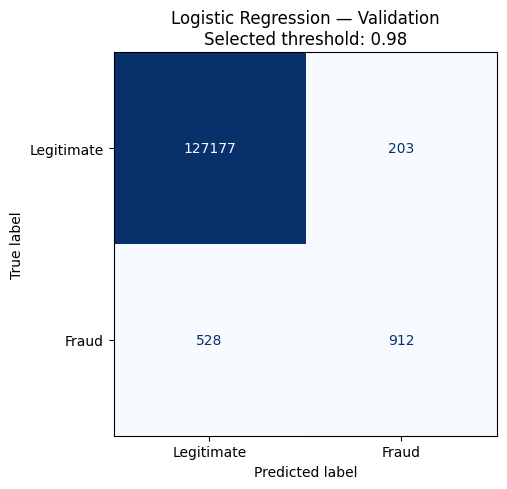

In [10]:
# Confusion matrix at the selected threshold
cm = confusion_matrix(y_val, lr_predictions, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Legitimate", "Fraud"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Logistic Regression — Validation\nSelected threshold: {lr_threshold:.2f}")
fig.tight_layout()
fig.savefig(OUT / "r2_lr_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame(
    cm,
    index=["actual_legitimate", "actual_fraud"],
    columns=["predicted_legitimate", "predicted_fraud"]
).to_csv(OUT / "r2_lr_confusion_matrix.csv")

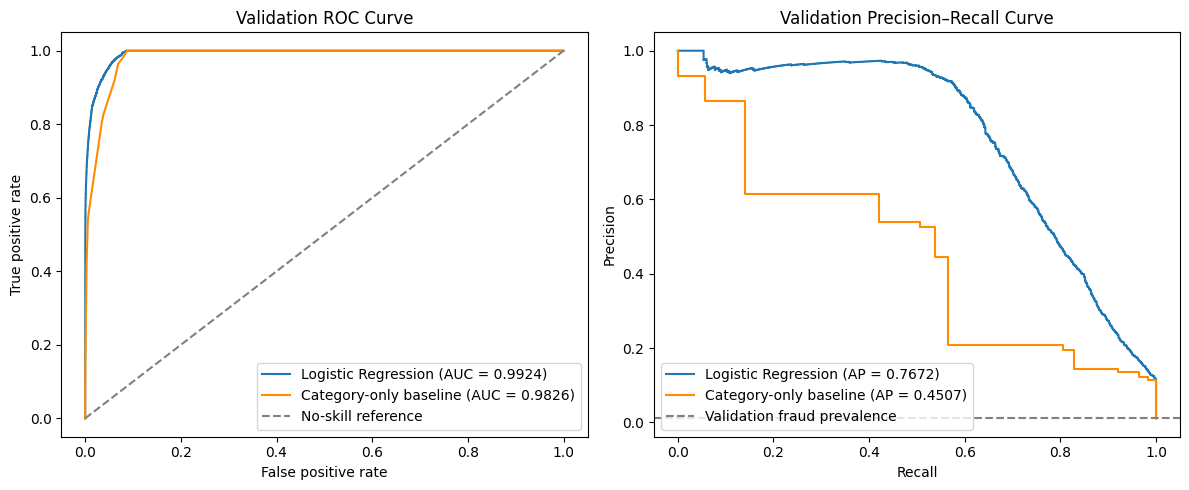

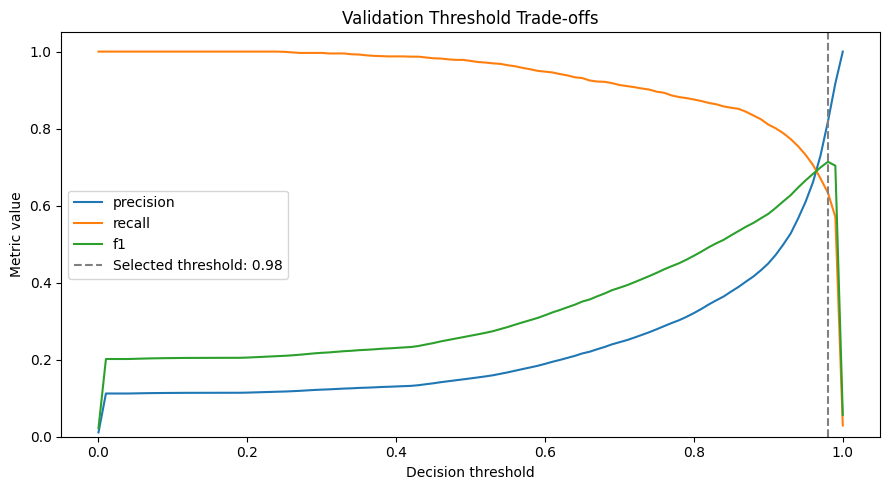

In [11]:
# ROC and precision-recall curves, with the category-only baseline for reference
fpr, tpr, _ = roc_curve(y_val, lr_scores)
precision_curve, recall_curve, _ = precision_recall_curve(y_val, lr_scores)
base_fpr, base_tpr, _ = roc_curve(y_val, category_scores)
base_precision, base_recall, _ = precision_recall_curve(y_val, category_scores)

lr_auc = roc_auc_score(y_val, lr_scores)
lr_ap = average_precision_score(y_val, lr_scores)
base_auc = roc_auc_score(y_val, category_scores)
base_ap = average_precision_score(y_val, category_scores)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"Logistic Regression (AUC = {lr_auc:.4f})")
axes[0].plot(base_fpr, base_tpr, color="darkorange",
             label=f"Category-only baseline (AUC = {base_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="No-skill reference")
axes[0].set_title("Validation ROC Curve")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend()

axes[1].step(recall_curve, precision_curve, where="post",
             label=f"Logistic Regression (AP = {lr_ap:.4f})")
axes[1].step(base_recall, base_precision, where="post", color="darkorange",
             label=f"Category-only baseline (AP = {base_ap:.4f})")
axes[1].axhline(y_val.mean(), linestyle="--", color="gray",
                label="Validation fraud prevalence")
axes[1].set_title("Validation Precision–Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUT / "r2_lr_validation_curves.png", dpi=200, bbox_inches="tight")
plt.show()

# Threshold trade-offs
fig, ax = plt.subplots(figsize=(9, 5))
for metric in ["precision", "recall", "f1"]:
    ax.plot(lr_table["threshold"], lr_table[metric], label=metric)
ax.axvline(lr_threshold, color="gray", linestyle="--",
           label=f"Selected threshold: {lr_threshold:.2f}")
ax.set_title("Validation Threshold Trade-offs")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Metric value")
ax.set_ylim(0, 1.05)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "r2_lr_threshold_tradeoffs.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
MODEL_FILE = MODEL_DIR / "r2_logistic_regression_pipeline.joblib"
joblib.dump(model, MODEL_FILE)

# Transaction-level validation predictions
prediction_export = validation[
    ["transaction_id", "step", "amount", "category", "fraud"]
].rename(columns={"fraud": "actual_fraud"}).copy()

prediction_export["model_score"] = lr_scores
prediction_export["predicted_fraud"] = lr_predictions
prediction_export["threshold"] = lr_threshold
prediction_export["partition"] = "validation"
prediction_export.to_csv(OUT / "r2_lr_validation_predictions.csv", index=False)

# Settings and rules, so the run can be explained and reproduced
run_details = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "BankSim synthetic transactions",
    "features": FEATURES,
    "target": "fraud",
    "training_steps": [0, TRAIN_END_STEP - 1],
    "validation_steps": [TRAIN_END_STEP, VALIDATION_END_STEP - 1],
    "reserved_test_steps": [VALIDATION_END_STEP, 179],
    "training_rows": len(train),
    "validation_rows": len(validation),
    "class_weight": "balanced",
    "solver": "lbfgs",
    "C": 1.0,
    "max_iter": 2000,
    "random_state": RANDOM_STATE,
    "training_seconds": training_seconds,
    "selected_threshold": lr_threshold,
    "threshold_rule": (
        "Maximum validation F1 on thresholds 0.00–1.00 "
        "in steps of 0.01; ties: higher precision, then higher threshold."
    ),
    "baselines": ["Always legitimate", "Category-only (training fraud rate per category)"],
    "test_evaluated": False,
    "calibration_performed": False,
    "python_version": sys.version.split()[0],
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "joblib_version": joblib.__version__
}

(OUT / "r2_lr_run_details.json").write_text(
    json.dumps(run_details, indent=2), encoding="utf-8"
)

print("Saved model:", MODEL_FILE)
print("Saved validation predictions and run details:", OUT)

Saved model: C:\Users\tiwar\Documents\RiskLens\models\r2_logistic_regression_pipeline.joblib
Saved validation predictions and run details: C:\Users\tiwar\Documents\RiskLens\outputs\R2


In [14]:
expected_files = [
    "r2_partition_check.csv",
    "sql_overall_totals.csv", "sql_split_summary.csv", "sql_training_category.csv",
    "sql_training_step.csv", "sql_training_amount.csv",
    "risklens_queries.sql", "sql_verification.txt",
    "r2_lr_validation_thresholds.csv", "r2_validation_model_metrics.csv",
    "r2_lr_operating_points.csv",
    "r2_lr_confusion_matrix.png", "r2_lr_confusion_matrix.csv",
    "r2_lr_validation_curves.png", "r2_lr_threshold_tradeoffs.png",
    "r2_lr_validation_predictions.csv", "r2_lr_run_details.json"
]

missing_files = [name for name in expected_files if not (OUT / name).is_file()]
assert not missing_files, f"Missing outputs: {missing_files}"
assert MODEL_FILE.is_file()

# The saved predictions must reproduce the confusion matrix.
saved = pd.read_csv(OUT / "r2_lr_validation_predictions.csv")
assert (
    ((saved["actual_fraud"] == 1) & (saved["predicted_fraud"] == 1)).sum() == cm[1, 1]
)
assert (
    ((saved["actual_fraud"] == 0) & (saved["predicted_fraud"] == 1)).sum() == cm[0, 1]
)

lr_row = metrics.loc[metrics["model"] == "Logistic Regression — selected threshold"].iloc[0]
base_row = metrics.loc[metrics["model"] == "Category-only baseline — selected threshold"].iloc[0]

print("PASS: all expected outputs are saved and consistent.\n")
print("NUMBERS FOR THE REPORT (all VALIDATION results)")
print(f"- Training: {len(train):,} transactions, {int(y_train.sum()):,} fraud (steps 0-107)")
print(f"- Validation: {len(validation):,} transactions, {int(y_val.sum()):,} fraud (steps 108-143)")
print(f"- Always legitimate: accuracy {metrics.iloc[0]['accuracy']:.2%}, recall 0")
print(f"- Category-only baseline: AP {base_row['average_precision']:.3f}, "
      f"F1 {base_row['f1']:.3f} at threshold {base_row['threshold']:.2f}")
print(f"- Logistic Regression: AP {lr_row['average_precision']:.3f}, "
      f"ROC-AUC {lr_row['roc_auc']:.3f}")
print(f"- At selected threshold {lr_threshold:.2f}: precision {lr_row['precision']:.3f}, "
      f"recall {lr_row['recall']:.3f}, F1 {lr_row['f1']:.3f}")
print(f"  caught {int(lr_row['true_positives'])} of {int(y_val.sum())} fraud cases, "
      f"missed {int(lr_row['false_negatives'])}, "
      f"{int(lr_row['false_positives'])} false alarms")
print("\nTest-set evaluation has NOT been performed.")
print("Save this notebook.")

PASS: all expected outputs are saved and consistent.

NUMBERS FOR THE REPORT (all VALIDATION results)
- Training: 332,592 transactions, 4,320 fraud (steps 0-107)
- Validation: 128,820 transactions, 1,440 fraud (steps 108-143)
- Always legitimate: accuracy 98.88%, recall 0
- Category-only baseline: AP 0.451, F1 0.532 at threshold 0.19
- Logistic Regression: AP 0.767, ROC-AUC 0.992
- At selected threshold 0.98: precision 0.818, recall 0.633, F1 0.714
  caught 912 of 1440 fraud cases, missed 528, 203 false alarms

Test-set evaluation has NOT been performed.
Save this notebook.
